# Práctica de búsqueda local — Colab base
## Fundamentos de Inteligencia Artificial

Este cuaderno contiene únicamente la estructura inicial. A partir de esta base deberás desarrollar Hill Climbing, Simulated Annealing, los experimentos y el análisis.

**Importante:** utiliza la función, dominio, punto inicial y parámetros indicados en la práctica asignada a tu grupo.


## 1. Librerías


In [14]:
import math
import random
import matplotlib.pyplot as plt


## 2. Función de trabajo

La siguiente función corresponde a una de las versiones. Si tu práctica tiene otra función, modifica únicamente esta celda.


In [15]:
def funcion(x):
    return 0.6*x + 8*math.sin(1.3*x) + 4*math.sin(2.4*x)


## 3. Dominio

Modifica los límites si tu práctica indica otro dominio.


In [16]:
x_min = 0
x_max = 20

valores_x = list(range(x_min, x_max + 1))


## 4. Tabla de valores


In [17]:
print(f"{'x':<5}{'f(x)':<10}")
print("-" * 15)

for x in valores_x:
    print(f"{x:<5}{funcion(x):<10.2f}")


x    f(x)      
---------------
0    0.00      
1    11.01     
2    1.34      
3    -0.53     
4    -5.36     
5    2.57      
6    15.45     
7    3.20      
8    -0.45     
9    0.83      
10   5.74      
11   18.31     
12   6.05      
13   -0.49     
14   6.83      
15   9.88      
16   19.61     
17   9.49      
18   0.09      
19   12.04     
20   15.03     


## 5. Gráfica de la función

Observa máximos locales, mínimos locales y regiones donde la función sube o baja.


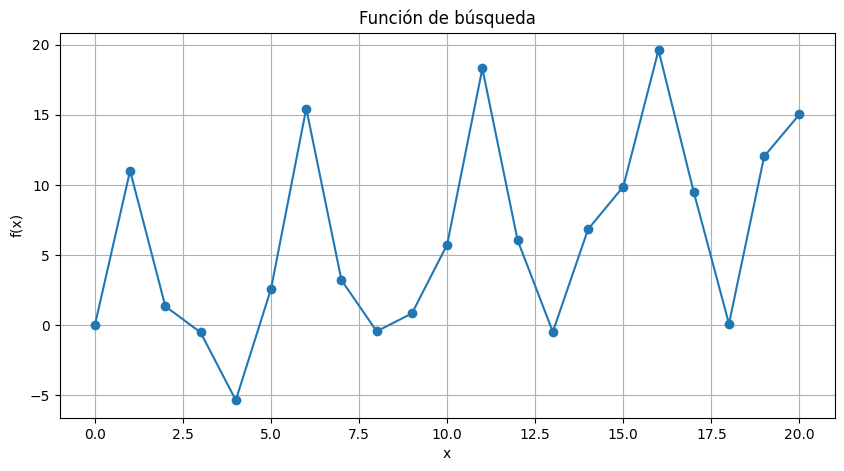

In [18]:
valores_y = [funcion(x) for x in valores_x]

plt.figure(figsize=(10,5))
plt.plot(valores_x, valores_y, marker='o')
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Función de búsqueda")
plt.grid(True)
plt.show()


# 6. Hill Climbing

Escribe aquí tu algoritmo Hill Climbing.


In [19]:

def hill_climbing(x0):
    actual = x0
    recorrido = [actual]

    while True:
        print(f"Estado actual: x={actual}, f(x)={funcion(actual):.2f}")

        vecinos = []
        if actual - 1 >= x_min:
            vecinos.append(actual - 1)
        if actual + 1 <= x_max:
            vecinos.append(actual + 1)

        mejor_vecino = vecinos[0]
        for v in vecinos:
            if funcion(v) > funcion(mejor_vecino):
                mejor_vecino = v

        print(f"Vecinos: {vecinos}, Mejor vecino: {mejor_vecino} con f(x)={funcion(mejor_vecino):.2f}")

        if funcion(mejor_vecino) > funcion(actual):
            actual = mejor_vecino
            recorrido.append(actual)
        else:
            print("Ningun vecino mejora la solucion actual. Deteniendo.")
            break

    return recorrido, actual, funcion(actual)


# 7. Resultados de Hill Climbing

Muestra recorrido, mejor x y f(x).


In [20]:
print("--- Resultados Hill Climbing ---")
x0 = 2
recorrido_hc, mejor_x_hc, mejor_fx_hc = hill_climbing(x0)

print("\nResumen:")
print(f"Recorrido: {recorrido_hc}")
print(f"Mejor x encontrado: {mejor_x_hc}")
print(f"Valor f(x) maximo: {mejor_fx_hc:.2f}")


--- Resultados Hill Climbing ---
Estado actual: x=2, f(x)=1.34
Vecinos: [1, 3], Mejor vecino: 1 con f(x)=11.01
Estado actual: x=1, f(x)=11.01
Vecinos: [0, 2], Mejor vecino: 2 con f(x)=1.34
Ningun vecino mejora la solucion actual. Deteniendo.

Resumen:
Recorrido: [2, 1]
Mejor x encontrado: 1
Valor f(x) maximo: 11.01


# 8. Simulated Annealing

Escribe aquí tu algoritmo Simulated Annealing.


In [31]:

def simulated_annealing(x0, T0, alpha, iteraciones):
    actual = x0
    mejor_solucion = x0
    T = T0
    recorrido = [actual]
    peores_aceptados = 0
    rechazados = 0

    for i in range(iteraciones):
        vecinos = []
        if actual - 1 >= x_min:
            vecinos.append(actual - 1)
        if actual + 1 <= x_max:
            vecinos.append(actual + 1)

        if not vecinos:
            continue

        vecino = random.choice(vecinos)
        delta = funcion(vecino) - funcion(actual)

        if delta >= 0:
            actual = vecino
            recorrido.append(actual)
            if funcion(actual) > funcion(mejor_solucion):
                mejor_solucion = actual
        else:
            p = math.exp(delta / T)
            r = random.random()
            if r < p:
                actual = vecino
                recorrido.append(actual)
                peores_aceptados += 1
            else:
                rechazados += 1

        T = alpha * T

    return mejor_solucion, funcion(mejor_solucion), recorrido, peores_aceptados, rechazados


# 9. Resultados de Simulated Annealing

Muestra mejor x, f(x), recorrido, peores aceptados y rechazados.


In [22]:
print("--- Resultados Simulated Annealing ---")
random.seed(25)
x0 = 2
T0 = 30
alpha = 0.97
iteraciones = 100

mejor_x_sa, mejor_fx_sa, recorrido_sa, peores_aceptados_sa, rechazados_sa = simulated_annealing(x0, T0, alpha, iteraciones)

print(f"Mejor x encontrado: {mejor_x_sa}")
print(f"Valor f(x) maximo: {mejor_fx_sa:.2f}")
print(f"Recorrido: {recorrido_sa}")
print(f"Movimientos peores aceptados: {peores_aceptados_sa}")
print(f"Movimientos rechazados: {rechazados_sa}")


--- Resultados Simulated Annealing ---
Mejor x encontrado: 6
Valor f(x) maximo: 15.45
Recorrido: [2, 3, 2, 1, 2, 1, 2, 3, 2, 1, 0, 1, 2, 1, 0, 1, 2, 3, 4, 5, 6, 5, 6, 7, 6, 5, 4, 3, 4, 5, 6, 5, 4, 3, 4, 3, 2, 1, 0, 1, 2, 3, 4, 3, 2, 3, 4, 3, 2, 1]
Movimientos peores aceptados: 24
Movimientos rechazados: 51


# 10. Comparación inicial

Compara los resultados de ambos algoritmos.


In [27]:
print(f"{'Algoritmo':<20}{'x inicial':<12}{'Mejor x':<10}{'f(x)':<10}{'¿Acepto empeoramientos?':<25}")
print("-" * 75)
print(f"{'Hill Climbing':<20}{2:<12}{mejor_x_hc:<10}{mejor_fx_hc:<10.2f}{'No':<25}")
print(f"{'Simulated Annealing':<20}{2:<12}{mejor_x_sa:<10}{mejor_fx_sa:<10.2f}{'Si':<25}")


Algoritmo           x inicial   Mejor x   f(x)      ¿Acepto empeoramientos?  
---------------------------------------------------------------------------
Hill Climbing       2           1         11.01     No                       
Simulated Annealing 2           6         15.45     Si                       


### Respuestas a la comparación inicial:

1. **¿Ambos algoritmos encontraron la misma solución?**
No. Encontraron máximos locales diferentes.

2. **¿Cuál obtuvo el mayor valor de f(x)?**
Simulated Annealing encontró un valor mejor.

3. **¿Por qué Hill Climbing se detuvo donde lo hizo?**
Porque llegó a un punto donde ninguno de sus vecinos (x-1, x+1) tenía un valor de f(x) mayor.

4. **¿Qué ventaja tuvo Simulated Annealing al poder aceptar algunos movimientos peores?**
Le permitió escapar del máximo local donde Hill Climbing se atoró.

# 11. Experimentos con temperatura inicial

Realiza aquí las pruebas con T0.


In [28]:
print("--- Experimento 1: Temperatura inicial ---")
print(f"{'T0':<5}{'Mejor x':<10}{'f(mejor)':<10}{'Peores aceptados':<20}{'Rechazados':<15}")
print("-" * 60)

temperaturas = [1, 5, 30, 60]
for t in temperaturas:
    random.seed(25)
    mx, mfx, rec, pa, r = simulated_annealing(2, t, 0.97, 100)
    print(f"{t:<5}{mx:<10}{mfx:<10.2f}{pa:<20}{r:<15}")


--- Experimento 1: Temperatura inicial ---
T0   Mejor x   f(mejor)  Peores aceptados    Rechazados     
------------------------------------------------------------
1    1         11.01     0                   99             
5    1         11.01     2                   95             
30   6         15.45     24                  51             
60   11        18.31     31                  37             


### Respuestas Experimento 1 (Temperatura Inicial):

* **¿Qué ocurre cuando la temperatura inicial es muy baja?**
El algoritmo rechaza casi todos los movimientos peores, por lo que actúa parecido a Hill Climbing.

* **¿Una temperatura mayor provoca más exploración?**
Sí, al principio acepta muchos movimientos peores, permitiendo explorar más el dominio.

* **¿Una temperatura muy alta garantiza encontrar el máximo global?**
No, ayuda a explorar, pero aún depende del azar y de cuántas iteraciones se hagan.

# 12. Experimentos con factor de enfriamiento

Realiza aquí las pruebas con alpha.


In [29]:
print("--- Experimento 2: Velocidad de enfriamiento ---")
print(f"{'alpha':<8}{'Mejor x':<10}{'f(mejor)':<10}{'Peores aceptados':<20}{'Rechazados':<15}")
print("-" * 65)

alphas = [0.70, 0.85, 0.97, 0.99]
for a in alphas:
    random.seed(25)
    mx, mfx, rec, pa, r = simulated_annealing(2, 30, a, 100)
    print(f"{a:<8}{mx:<10}{mfx:<10.2f}{pa:<20}{r:<15}")


--- Experimento 2: Velocidad de enfriamiento ---
alpha   Mejor x   f(mejor)  Peores aceptados    Rechazados     
-----------------------------------------------------------------
0.7     1         11.01     3                   93             
0.85    1         11.01     3                   93             
0.97    6         15.45     24                  51             
0.99    11        18.31     39                  22             


### Respuestas Experimento 2 (Velocidad de enfriamiento):

* **¿Qué sucede cuando alpha está más cerca de 1?**
El enfriamiento es más lento. La temperatura baja poco a poco, lo que hace que el algoritmo siga aceptando soluciones peores por más tiempo, explorando más.

# 13. Cambio del punto inicial

Realiza aquí las pruebas con distintos puntos iniciales.


In [32]:
print("--- Cambio del punto inicial ---")
print(f"{'Inicio':<10}{'HC: mejor x':<15}{'SA: mejor x':<15}")
print("-" * 40)

def hc_silencioso(x0):
    actual = x0
    while True:
        vecinos = []
        if actual - 1 >= x_min: vecinos.append(actual - 1)
        if actual + 1 <= x_max: vecinos.append(actual + 1)
        mejor_vecino = vecinos[0]
        for v in vecinos:
            if funcion(v) > funcion(mejor_vecino):
                mejor_vecino = v
        if funcion(mejor_vecino) > funcion(actual):
            actual = mejor_vecino
        else:
            break
    return actual

puntos_iniciales = [2, 7, 12, 18]
for p in puntos_iniciales:
    random.seed(25)
    mx_hc = hc_silencioso(p)
    mx_sa, _, _, _, _ = simulated_annealing(p, 30, 0.97, 100)
    print(f"{p:<10}{mx_hc:<15}{mx_sa:<15}")


--- Cambio del punto inicial ---
Inicio    HC: mejor x    SA: mejor x    
----------------------------------------
2         1              6              
7         6              6              
12        11             11             
18        20             16             


### Respuestas Cambio del punto inicial:

1. **¿Hill Climbing depende del punto inicial?**
Sí, mucho. Su resultado final está determinado por la colina (máximo local) más cercana a su punto de partida.

2. **¿Simulated Annealing también puede producir resultados diferentes?**
Sí, porque usa números aleatorios, pero al explorar más, tiene más chances de llegar a buenos resultados sin importar tanto el inicio.

3. **¿Aceptar soluciones peores elimina completamente el problema de los máximos locales?**
No lo elimina por completo, pero reduce enormemente la probabilidad de quedarse atascado en uno malo.

# 14. Análisis

Responde las preguntas de análisis indicadas en tu práctica.

1. **¿Cuál es la diferencia principal entre Hill Climbing y Simulated Annealing?**
La diferencia es que Hill Climbing solo avanza hacia mejores soluciones y se estanca fácil, mientras que Simulated Annealing puede dar "pasos hacia atrás" (aceptar peores soluciones) para intentar salir de un estancamiento.

2. **¿Qué representa un vecino en este problema?**
Es el número entero que está inmediatamente antes (x-1) o después (x+1) del número actual.

3. **¿Qué significa que Hill Climbing quede atrapado en un máximo local?**
Significa que llegó a la cima de una "colina pequeña". Todos los pasos a su alrededor van hacia abajo, así que piensa que llegó al tope y se detiene, sin darse cuenta de que hay una colina más alta más lejos.

4. **¿Por qué Simulated Annealing puede aceptar una solución peor?**
Para no quedarse atascado en la primera colina pequeña que encuentre (máximo local). Aceptar empeorar a veces le permite bajar de una colina para luego poder subir a otra más alta.

5. **¿Qué función cumple la temperatura T?**
Controla qué tan probable es que acepte una solución peor. Si T es alta, acepta casi todo (explora mucho). Si T es baja, casi no acepta empeorar (se enfoca en mejorar).

6. **¿Qué ocurre conforme disminuye T?**
El algoritmo se vuelve más "estricto". Al principio explora mucho, pero conforme T baja, empieza a comportarse más como Hill Climbing, buscando solo subir para afinar el resultado final.

7. **¿Por qué se debe guardar por separado la mejor solución encontrada y la solución actual?**
Porque como a veces aceptamos soluciones peores para explorar, la "solución actual" puede no ser la mejor que hemos visto. Necesitamos guardar la mejor por si acaso terminamos el ciclo estando en un punto bajo.

8. **¿Qué efecto tiene un valor de alpha cercano a 1?**
Hace que el enfriamiento sea muy lento. La temperatura baja poquito a poco, por lo que el algoritmo explora el espacio por más tiempo.

9. **¿Por qué dos ejecuciones de Simulated Annealing pueden obtener resultados distintos si no se utiliza la misma semilla?**
Porque usa números aleatorios para decidir si acepta un empeoramiento o no. Distintos números aleatorios provocan distintos caminos tomados.


# 15. Conclusión

Hill Climbing es un método rápido y sencillo, pero tiene el gran problema de que se queda atascado en el primer máximo local que encuentra cerca de su punto de inicio. En cambio, Simulated Annealing es un algoritmo más inteligente porque, al permitir pequeños empeoramientos al inicio (gracias a la temperatura alta), puede escapar de esas trampas locales y explorar más el terreno. Los parámetros como la temperatura inicial y el ritmo de enfriamiento (alpha) son clave: si enfriamos muy rápido, no exploramos lo suficiente; si enfriamos muy lento, tardará mucho. En conclusión, Simulated Annealing es mucho mejor para funciones con muchos "picos y valles", ya que tiene más posibilidades de encontrar el punto más alto de todos.
